# **03 - Evaluasi dan Submission**
Mengevaluasi model terlatih pada data validasi (akurasi, laporan per kelas, confusion matrix), lalu memprediksi test set dan menulis `submission.csv`.

1. **Setup dan lokasi data**

Mengimpor library dasar, menetapkan nama kompetisi, lalu mencari folder dataset di Kaggle. Data kompetisi ter-*mount* di `/kaggle/input/competitions/<slug>` (kode juga mencoba lokasi alternatif). Variabel `WORK` adalah folder keluaran (`/kaggle/working`), `CLASS_NAMES` adalah 16 kelas sesuai urutan `label` 0-15, dan `SEED` dipakai agar hasil bisa diulang.

**Hasil:** `DATA_DIR` terdeteksi di `/kaggle/input/competitions/document-image-classification-sd234504`.

In [ ]:
import os, time, random, warnings, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

COMP = "document-image-classification-sd234504"
CANDIDATES = [Path(f"/kaggle/input/{COMP}"), Path(f"/kaggle/input/competitions/{COMP}")]
DATA_DIR = next((p for p in CANDIDATES if (p / "train.csv").exists()), None)
if DATA_DIR is None:
    hits = [h for pat in ("*/train.csv", "*/*/train.csv", "*/*/*/train.csv") for h in glob.glob("/kaggle/input/" + pat)]
    assert hits, "Dataset kompetisi belum ditambahkan! Klik 'Add Input' -> tab Competition."
    DATA_DIR = Path(hits[0]).parent
WORK = Path("/kaggle/working")
CLASS_NAMES = ["advertisement", "budget", "email", "file_folder", "form", "handwritten",
               "invoice", "letter", "memo", "news_article", "presentation", "questionnaire",
               "resume", "scientific_publication", "scientific_report", "specification"]
SEED = 42
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /kaggle/input/competitions/document-image-classification-sd234504


2. **Fungsi inti**

Blok-blok kode berikut sama dengan notebook training (cache, dataset, model, evaluasi), diperlukan agar arsitektur dan preprocessing saat evaluasi identik dengan saat training.

2.1. **Impor, konstanta, dan device**
Mengimpor PyTorch dan utilitas pendukung, lalu menetapkan konstanta: jumlah kelas (16), ukuran input 224x224 piksel (sesuai DiT), nama backbone `microsoft/dit-base`, ukuran batch 32, porsi validasi 10%, jumlah worker DataLoader 2, dan `DEVICE` (GPU jika ada, selain itu CPU).

In [ ]:
import torch, torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset

NUM_CLASSES = len(CLASS_NAMES)
SIZE = 224
MODEL_NAME = "microsoft/dit-base"
BATCH_SIZE, VAL_FRACTION, NUM_WORKERS = 32, 0.1, 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

2.2. **Fungsi `seed_everything`**

Mengunci seed Python, NumPy, dan PyTorch agar pembagian data dan inisialisasi head model sama setiap kali dijalankan (*reproducible*).

In [ ]:
def seed_everything(seed):
    """Set seed Python, NumPy, dan PyTorch agar hasil reproducible."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

2.3. **Fungsi membaca gambar: `resolve_path`, `load_image`, `prep_image`**

- `resolve_path`: mencari lokasi file gambar karena path di CSV (`train/...`) bisa berbeda dari struktur folder di disk.
- `load_image`: membuka TIFF dengan beberapa decoder cadangan (Pillow, lalu tifffile). Jika file korup/terpotong, diganti halaman putih agar proses tidak berhenti.
- `prep_image`: mengubah satu gambar menjadi grayscale 224x224 (array uint8) yang siap disimpan di cache.

In [ ]:
def resolve_path(root, filename):
    """Mencari lokasi file gambar di disk.

    CSV menulis ``train/invoice/x.tif`` sedangkan di disk bisa ``train/train/invoice/x.tif``.

    Args:
        root: Folder dataset.
        filename: Kolom ``filename`` dari CSV.

    Returns:
        Path file yang ditemukan.
    """
    root = Path(root)
    for p in (root / filename, root / filename.split("/")[0] / filename):
        if p.exists():
            return p
    raise FileNotFoundError(f"{filename} tidak ditemukan di {root}")


def load_image(path):
    """Membuka gambar dengan fallback decoder; file korup diganti halaman putih.

    Args:
        path: Lokasi file gambar.

    Returns:
        Citra PIL mode RGB.
    """
    try:
        return Image.open(path).convert("RGB")
    except Exception:
        pass
    try:
        import tifffile
        return Image.fromarray(tifffile.imread(str(path))).convert("RGB")
    except Exception:
        pass
    warnings.warn(f"Gambar tidak terbaca, diganti halaman putih: {path}")
    return Image.new("RGB", (224, 224), (255, 255, 255))


def prep_image(path, size=SIZE):
    """Decode satu gambar -> grayscale uint8 ``size`` x ``size``."""
    img = load_image(path).convert("L").resize((size, size), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

2.4. **Fungsi cache gambar: `find_existing` dan `build_cache`**

- `find_existing`: mencari file hasil run sebelumnya (mis. cache atau `best.pt`) di `/kaggle/working` atau di input notebook lain.
- `build_cache`: men-decode semua gambar sekali (paralel dengan beberapa thread) dan menyimpannya sebagai satu array `.npy`. Epoch berikutnya cukup membaca array ini, sehingga jauh lebih cepat daripada membuka TIFF berulang kali. Jika cache sudah ada, langsung dipakai ulang.

In [ ]:
def find_existing(name):
    """Mencari file hasil run sebelumnya (di /kaggle/working atau di input notebook lain).

    Returns:
        Path file jika ada, selain itu None.
    """
    for pattern in (str(WORK / name), f"/kaggle/input/*/{name}", f"/kaggle/input/*/*/{name}", f"/kaggle/input/*/*/*/{name}"):
        hits = glob.glob(pattern)
        if hits:
            return Path(hits[0])
    return None


def build_cache(df, name, workers=4):
    """Membuat (atau memakai ulang) cache array gambar uint8 (N, 224, 224).

    Args:
        df: DataFrame dengan kolom ``filename``.
        name: Nama file cache ``.npy``.
        workers: Jumlah thread decoding.

    Returns:
        Path file cache.
    """
    found = find_existing(name)
    if found is not None:
        print("Memakai cache:", found)
        return found
    path = WORK / name
    paths = [resolve_path(DATA_DIR, f) for f in df["filename"]]
    arr = np.lib.format.open_memmap(path, mode="w+", dtype=np.uint8, shape=(len(paths), SIZE, SIZE))
    with ThreadPoolExecutor(workers) as ex:
        for i, a in enumerate(tqdm(ex.map(prep_image, paths), total=len(paths), desc=name)):
            arr[i] = a
    arr.flush()
    return path

2.5. **Kelas `CachedDataset`**

Dataset PyTorch yang membaca gambar dari cache. Setiap gambar dinormalisasi (mean 0,5, std 0,5) dan diulang ke 3 channel sesuai input DiT. Pada mode `train=True`, ditambahkan augmentasi geser acak kecil (hingga 8 piksel) untuk meniru pergeseran pada dokumen hasil pindai.

In [ ]:
class CachedDataset(Dataset):
    """Dataset dari cache: normalisasi (mean 0.5, std 0.5), 3 channel, augmentasi geser ringan.

    Args:
        cache_path: File ``.npy`` hasil ``build_cache``.
        labels: Array label (None untuk test).
        train: Jika True, aktifkan augmentasi geser acak kecil.
    """

    def __init__(self, cache_path, labels=None, train=False):
        """Memuat cache (memory-mapped) dan menyimpan label."""
        self.arr = np.load(cache_path, mmap_mode="r")
        self.labels, self.train = labels, train

    def __len__(self):
        """Jumlah sampel."""
        return len(self.arr)

    def __getitem__(self, i):
        """Mengambil satu sampel: ``(tensor, label)`` atau hanya tensor bila tanpa label."""
        x = torch.from_numpy(np.array(self.arr[i])).float().div_(255.0)
        if self.train:
            dx, dy = np.random.randint(-8, 9, size=2)
            x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(0, 1))
        x = ((x - 0.5) / 0.5).unsqueeze(0).expand(3, -1, -1).contiguous()
        return x if self.labels is None else (x, torch.tensor(int(self.labels[i])))

2.6. **Fungsi DataLoader: `build_loaders` dan `build_test_loader`**

- `build_loaders`: membuat cache train, membagi data menjadi train dan validasi dengan *stratified split* (proporsi kelas terjaga, seed tetap), lalu membungkusnya menjadi DataLoader.
- `build_test_loader`: membuat cache test dan DataLoader untuk prediksi akhir (tanpa label).

In [ ]:
def build_loaders():
    """Membuat DataLoader train & validasi (stratified split) dari train.csv.

    Returns:
        Tuple ``(train_loader, val_loader, train_df)``.
    """
    df = pd.read_csv(DATA_DIR / "train.csv")
    cache = build_cache(df, f"cache_train_{SIZE}.npy")
    tr_i, va_i = train_test_split(np.arange(len(df)), test_size=VAL_FRACTION,
                                  stratify=df["label"], random_state=SEED)
    y = df["label"].values
    train = Subset(CachedDataset(cache, y, train=True), tr_i)
    val = Subset(CachedDataset(cache, y), va_i)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=True)
    return (DataLoader(train, BATCH_SIZE, shuffle=True, drop_last=True, **kw),
            DataLoader(val, BATCH_SIZE * 2, **kw), df)


def build_test_loader():
    """Membuat DataLoader untuk test.csv.

    Returns:
        Tuple ``(test_loader, test_df)``.
    """
    df = pd.read_csv(DATA_DIR / "test.csv")
    cache = build_cache(df, f"cache_test_{SIZE}.npy")
    return DataLoader(CachedDataset(cache), BATCH_SIZE * 2, num_workers=NUM_WORKERS, pin_memory=True), df

2.7. **Fungsi `build_model`**

Memuat backbone Transformer `microsoft/dit-base` (pre-trained pada dokumen) dan mengganti head klasifikasi menjadi 16 kelas kompetisi. Bobot head baru diinisialisasi acak, sedangkan bobot backbone dipertahankan lalu di-*fine-tune*.

In [ ]:
def build_model(name=MODEL_NAME):
    """Membuat model Transformer pre-trained dengan head baru 16 kelas.

    Args:
        name: Nama model di HuggingFace Hub.

    Returns:
        Model PyTorch (keluaran logits (B, 16)).
    """
    from transformers import AutoModelForImageClassification
    return AutoModelForImageClassification.from_pretrained(
        name, num_labels=NUM_CLASSES, id2label=dict(enumerate(CLASS_NAMES)),
        label2id={c: i for i, c in enumerate(CLASS_NAMES)}, ignore_mismatched_sizes=True)

2.8. **Fungsi `evaluate`**

Menghitung loss dan akurasi model pada DataLoader berlabel (mode evaluasi, tanpa gradien, dengan mixed precision). Mengembalikan loss, akurasi, label sebenarnya, dan label prediksi, yang dipakai untuk laporan per kelas dan confusion matrix.

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    """Mengevaluasi model pada DataLoader berlabel.

    Returns:
        Tuple ``(loss, akurasi, y_true, y_pred)``.
    """
    model.eval()
    loss, ys, ps = 0.0, [], []
    for x, y in tqdm(loader, leave=False, desc="eval"):
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(pixel_values=x.to(DEVICE)).logits.float().cpu()
        loss += F.cross_entropy(logits, y, reduction="sum").item()
        ys.append(y); ps.append(logits.argmax(-1))
    yt, yp = torch.cat(ys), torch.cat(ps)
    return loss / len(yt), (yt == yp).float().mean().item(), yt.numpy(), yp.numpy()

3. **Memuat checkpoint**

Membangun arsitektur model, lalu memuat bobot terbaik `best.pt` hasil training dan memindahkannya ke GPU.

**Hasil:** checkpoint ditemukan di `/kaggle/working/best.pt` dan model berjalan di `cuda`. Keluaran panjang di bawah hanya struktur model (`BeitForImageClassification`) dan load report yang sama seperti di notebook training.

In [ ]:
seed_everything(SEED)
ckpt = find_existing("best.pt")
assert ckpt is not None, "best.pt tidak ditemukan: tambahkan output notebook training lewat Add Input -> Notebooks."
print("Checkpoint:", ckpt, "| Device:", DEVICE)
model = build_model()
model.load_state_dict(torch.load(ckpt, map_location="cpu")); model.to(DEVICE)

Checkpoint: /kaggle/working/best.pt | Device: cuda


[transformers] BeitForImageClassification LOAD REPORT from: microsoft/dit-base
Key                          | Status     | 
-----------------------------+------------+-
lm_head.bias                 | UNEXPECTED | 
layernorm.weight             | UNEXPECTED | 
layernorm.bias               | UNEXPECTED | 
lm_head.weight               | UNEXPECTED | 
beit.pooler.layernorm.bias   | MISSING    | 
beit.pooler.layernorm.weight | MISSING    | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BeitForImageClassification(
  (beit): BeitModel(
    (embeddings): BeitEmbeddings(
      (patch_embeddings): BeitPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0): BeitLayer(
        (attention): BeitAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=False)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): BeitMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, ou

4. **Evaluasi pada data validasi**

4.1. **DataLoader Validasi**

Membuat ulang DataLoader validasi (split yang sama dengan training karena seed dan stratifikasi identik), menghitung loss dan akurasi, lalu mencetak laporan klasifikasi per kelas (precision, recall, F1).

**Hasil:** val loss 0,4995 dan **akurasi 86,38%** pada 3.201 gambar, sama dengan nilai terbaik saat training (macro F1 0,864).
- **Terbaik (F1):** *email* 0,988, *resume* 0,954, *handwritten* 0,942, *memo* 0,925.
- **Terlemah (F1):** *form* 0,677, *scientific_report* 0,721, *presentation* 0,778.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
_, val_loader, _ = build_loaders()
vl, va, y_true, y_pred = evaluate(model, val_loader)
print(f"val_loss={vl:.4f} val_acc={va:.4f}")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

Memakai cache: /kaggle/working/cache_train_224.npy


val_loss=0.4995 val_acc=0.8638
                        precision    recall  f1-score   support

         advertisement      0.882     0.896     0.889       201
                budget      0.821     0.801     0.811       201
                 email      0.980     0.995     0.988       201
           file_folder      0.877     0.916     0.896       202
                  form      0.693     0.662     0.677       201
           handwritten      0.928     0.956     0.942       203
               invoice      0.848     0.874     0.861       198
                letter      0.874     0.919     0.896       197
                  memo      0.952     0.899     0.925       199
          news_article      0.886     0.832     0.859       197
          presentation      0.749     0.809     0.778       199
         questionnaire      0.838     0.821     0.829       195
                resume      0.984     0.926     0.954       203
scientific_publication      0.899     0.903     0.901       206
     sci

4.2. **Fungsi `plot_confusion_matrix`**

Menggambar confusion matrix yang dinormalisasi per baris (tiap baris = kelas sebenarnya, nilai = proporsi prediksi), dan opsional menyimpannya sebagai gambar.

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, path=None):
    """Menggambar confusion matrix ternormalisasi per baris.

    Args:
        y_true: Label sebenarnya.
        y_pred: Label prediksi.
        class_names: Nama kelas.
        path: Jika diberikan, gambar disimpan ke path ini.
    """
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names,
                yticklabels=class_names, ax=ax, cbar=False)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya"); fig.tight_layout()
    if path: fig.savefig(path, dpi=150)
    plt.show()

4.3. **Confusion matrix dan pasangan kelas yang tertukar**

Menampilkan confusion matrix, menyimpannya ke `confusion_matrix.png`, lalu mendaftar 10 pasangan kesalahan terbanyak (kelas sebenarnya dan kelas yang diprediksi).

**Hasil:** kesalahan terbanyak adalah *form* diprediksi *invoice* (20), *scientific_report* diprediksi *presentation* (19), *presentation* diprediksi *scientific_report* (15), dan *scientific_report* diprediksi *form* (14). Kesalahan lain: *news_article* ke *presentation* (12), *budget* ke *form* (10), dan *memo* ke *letter* (10).

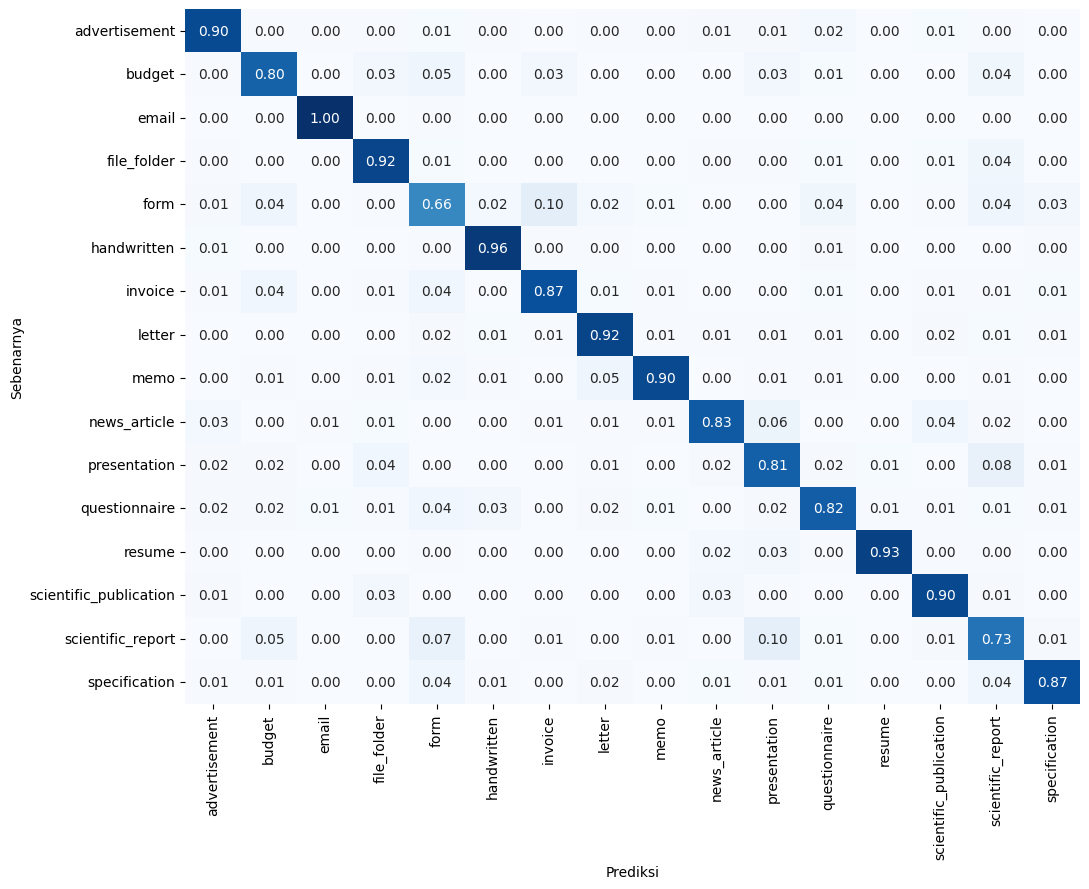

,sebenarnya,diprediksi,jumlah
0,form,invoice,20
1,scientific_report,presentation,19
2,presentation,scientific_report,15
3,scientific_report,form,14
4,news_article,presentation,12
5,budget,form,10
6,memo,letter,10
7,scientific_report,budget,10
8,form,budget,9
9,form,scientific_report,9


In [ ]:
plot_confusion_matrix(y_true, y_pred, CLASS_NAMES, WORK / "confusion_matrix.png")

cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i in range(16) for j in range(16) if cm[i, j] > 0]
pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:10], columns=["sebenarnya", "diprediksi", "jumlah"])

5. **Prediksi test set dan submission**

5.1. **Fungsi `predict_probs`**

Menghitung probabilitas softmax 16 kelas untuk setiap gambar di sebuah DataLoader (tanpa gradien, mixed precision), dikembalikan sebagai array (N, 16).

In [ ]:
@torch.no_grad()
def predict_probs(model, loader):
    """Menghitung probabilitas softmax untuk seluruh DataLoader.

    Returns:
        Array (N, 16).
    """
    model.eval(); out = []
    for x in tqdm(loader, desc="test"):
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            out.append(model(pixel_values=x.to(DEVICE)).logits.float().softmax(-1).cpu())
    return torch.cat(out).numpy()

5.2. **Prediksi test set dan penulisan `submission.csv`**

Membuat cache dan DataLoader test, memprediksi seluruh gambar, menyimpan probabilitas ke `test_probs.npy`, lalu mengambil kelas dengan probabilitas tertinggi (`argmax`) sebagai label dan menulis `submission.csv` berformat `id,label`.

**Hasil:** 7.994 baris prediksi (sesuai jumlah gambar test), dengan contoh baris awal ditampilkan.

In [ ]:
test_loader, test_df = build_test_loader()
probs = predict_probs(model, test_loader)
np.save(WORK / "test_probs.npy", probs)
sub = pd.DataFrame({"id": test_df["id"], "label": probs.argmax(1)})
sub.to_csv(WORK / "submission.csv", index=False)
print(sub.shape); sub.head()

(7994, 2)


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,1
3,test_00004,6
4,test_00005,13


5.3. **Validasi format submission**
Memastikan kolom, jumlah baris, dan urutan `id` identik dengan `sample_submission.csv`, lalu menghitung distribusi label prediksi.

**Hasil:** format sesuai (`Format OK`). Prediksi tersebar merata, 452 sampai 541 per kelas, dekat dengan 7.994 / 16 ≈ 500, yang wajar jika test set juga seimbang seperti data latih. Tidak ada kelas yang mendominasi atau hilang.

In [ ]:
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert list(sub.columns) == list(sample.columns) and len(sub) == len(sample) and (sub.id == sample.id).all()
print("Format OK. Distribusi prediksi:"); sub.label.value_counts().sort_index()

Format OK. Distribusi prediksi:


label
0     498
1     464
2     508
3     529
4     502
5     511
6     517
7     502
8     479
9     452
10    535
11    470
12    492
13    513
14    541
15    481
Name: count, dtype: int64

6. **Interpretasi hasil evaluasi**

- **Performa:** akurasi validasi 86,38% (macro F1 0,864), jauh di atas tebakan acak (6,25%).
- **Kelas mudah:** *email*, *resume*, *handwritten*, dan *memo* dikenali dengan baik karena punya ciri visual khas (kepala surel, struktur CV, tulisan tangan, judul *MEMORANDUM*).
- **Kelas sulit:** *form* (F1 0,677) sering tertukar dengan *invoice*, *budget*, dan *scientific_report*, karena sama-sama berisi tabel dan kolom isian. *Scientific_report* dan *presentation* saling tertukar, kemungkinan karena keduanya berupa halaman teks padat dengan struktur judul dan poin yang mirip pada resolusi 224x224. Pasangan *memo*-*letter* juga tertukar karena tata letaknya mirip.
- **Keterbatasan:** resize ke 224x224 menghilangkan detail teks kecil, padahal beberapa kelas dibedakan oleh kata kunci. Skor test perlu dibandingkan dengan akurasi validasi 86,38% untuk menilai generalisasi.
- **Perbaikan lanjutan:** resolusi lebih tinggi, test-time augmentation, ensemble model, dan fitur teks dari OCR.